# Tutorial 1: is this region supported by the data, and which genes explain it?

A drawn region on a Visium section, explained scale by scale.

Data: human dorsolateral prefrontal cortex, section 151673 (Maynard et al., *Nat. Neurosci.* 2021), with the published layer annotations. Put `filtered_feature_bc_matrix.h5` and a `spots.csv` with columns `barcode, in_tissue, array_row, array_col, pixel_row, pixel_col, layer` in `tutorials/data/151673/`. The matrix is the standard Space Ranger output; the layer column comes from the spatialLIBD annotations.

What you get at the end:

1. a **coherence score** for the layer-1 region, with a chance reference (the same outline put down elsewhere; random blobs of the same size);
2. a **gene list** in which every gene carries a scale label and a contribution map;
3. a demonstration that the score **falls when the region is moved by one spot, and much less when it is grown**.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.spatial import cKDTree
import scalematch as sm
from scalematch.plotting import plot_target_bands, plot_curves, plot_contributions

counts, genes, coords, pos = sm.read_visium("data/151673/filtered_feature_bc_matrix.h5", "data/151673/spots.csv")
# keep the largest connected component of the spot lattice (drops a few isolated spots)
A, L, keep, pitch_px = sm.build_graph(coords)
counts, coords, pos = counts[keep], coords[keep], pos[keep].reset_index(drop=True)
print(counts.shape, "spots x genes;", "layers:", pos.layer.value_counts().to_dict())

(3621, 33538) spots x genes; layers: {'L3': 989, 'L6': 692, 'L5': 673, 'WM': 513, 'L1': 267, 'L2': 253, 'L4': 218}


## 1. The target

The region is the published layer-1 annotation, as a 0/1 vector over the spots. Coordinates are in full-resolution pixels; the only physical number the method needs is the centre-to-centre spacing, 100 µm for Visium.

Bands are set in micrometres. Visium's 100 µm pitch can represent nothing shorter than 200 µm (its sampling limit), so for Visium we use σ = 70 and 200 µm: LOW is structure wider than 200 µm, MID is the 70–200 µm band at the edge of what the lattice resolves, HIGH is spot-to-spot variation.

In [2]:
region = (pos.layer == "L1").to_numpy()
print("L1 spots:", region.sum(), "of", len(region))

res = sm.explain(counts, genes, coords, region, pitch_um=100, sigmas=(70, 200),
                 designs=("perband", "raw"), null_kinds=("rigid", "blob"), n_null=20, seed=0)
print(res.summary())

L1 spots: 267 of 3621
[scalematch     0s] graph: 3621 units kept of 3621, pitch 137.00 units = 100 um


[scalematch     1s] dictionary: 500 genes, 0 excluded by name


[scalematch     2s] bands done; target shares LOW 0.74, MID 0.05, HIGH 0.03


[scalematch     2s] strips: [724, 724, 724, 724, 725] units, region units per strip [38, 0, 41, 90, 98]


[scalematch     2s] perband: A 0.547 best 0.614 | explained LOW 0.74, MID 0.05, HIGH -0.11


[scalematch     3s] raw: A 0.281 best 0.381 | explained LOW 0.61, MID -0.28, HIGH -2.65


[scalematch    23s] null rigid: 20 draws scored


[scalematch    43s] null blob: 20 draws scored


[scalematch    43s] attribution done: APBB1, MALAT1, STMN4, HPCAL1, EEF2, MUC1, MORF4L2, S100A6


region target on 3621 units, pitch 100 um, bands 70/200 um
held-out: A = 0.547, best 1-NMSE = 0.614 at k = 17
explained per band (held-out): LOW 0.74, MID 0.05, HIGH -0.11
target band shares: LOW 0.74, MID 0.05, HIGH 0.03
perband/rigid/A: p = 0.048, excess over null mean = +0.510 (n = 20)
perband/rigid/best: p = 0.048, excess over null mean = +0.562 (n = 20)
perband/rigid/explained_MID: p = 0.048, excess over null mean = +0.311 (n = 20)
perband/blob/A: p = 0.048, excess over null mean = +0.421 (n = 20)
perband/blob/best: p = 0.048, excess over null mean = +0.424 (n = 20)
perband/blob/explained_MID: p = 0.048, excess over null mean = +0.507 (n = 20)
top genes (order, dominant band): APBB1 (LOW), MALAT1 (LOW), STMN4 (LOW), HPCAL1 (LOW), EEF2 (LOW), MUC1 (LOW), MORF4L2 (LOW), S100A6 (LOW), SLC1A2 (LOW), YWHAB (LOW)


Reading the summary, three questions:

* **Real?** `p` and `excess`. The same outline turned, flipped and placed elsewhere (`rigid`) scores 0.05 on average; layer 1 scores 0.61 (`excess` +0.56). Random connected regions of the same size (`blob`) say the same. p = 0.048 is the floor for 20 draws: none of the 20 copies came close.
* **How big?** `explained per band`: LOW 0.74, MID 0.05, HIGH −0.11. Layer 1 is a broad band; what the genes reproduce is its body (> 200 µm), nothing finer. On Visium nothing finer than 200 µm is representable in the first place.
* **Which genes?** every selected gene is LOW-dominant; `rms_LOW` ranks them (section 2).

Supporting detail: `strips` are cut across the region's own axis, so every held-out strip holds part of layer 1 and the fit is tested by interpolation, not by extrapolating to a part of the tissue it never saw. `A` is the mean of the held-out curve over k = 1…30 genes and `best` its peak, so `A` is high when a few genes already do well. `excess` is the observed value minus the null mean.

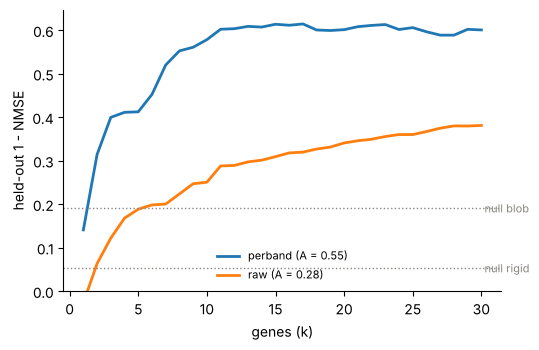

In [3]:
fig = plot_curves(res)

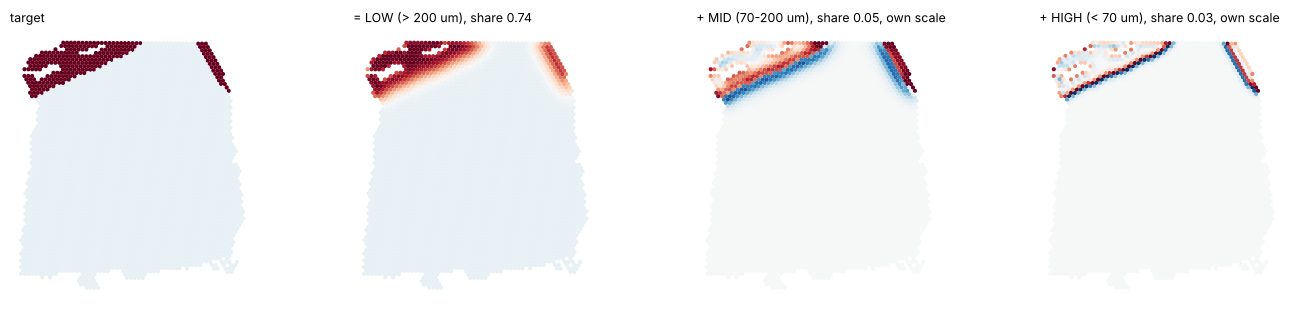

In [4]:
fig = plot_target_bands(res, s=9)

## 2. The genes

The band-matched fit on all spots gives, for every selected gene, a contribution vector per band (standardised band-filtered expression times its coefficient, in target units). `gene_table` lists the genes in the order they entered, with the RMS of each contribution per band and the band that dominates.

In [5]:
res.gene_table.head(12)[["order", "gene", "rms_LOW", "rms_MID", "rms_HIGH", "dominant"]].round(3)

,order,gene,rms_LOW,rms_MID,rms_HIGH,dominant
0,1,APBB1,0.028,0.000,0.002,LOW
1,2,MALAT1,0.088,0.003,0.002,LOW
2,3,STMN4,0.029,0.002,0.001,LOW
3,4,HPCAL1,0.016,0.010,0.001,LOW
4,5,EEF2,0.020,0.002,0.001,LOW
5,6,MUC1,0.060,0.004,0.002,LOW
6,7,MORF4L2,0.028,0.002,0.001,LOW
7,8,S100A6,0.025,0.001,0.001,LOW
8,9,SLC1A2,0.076,0.004,0.001,LOW
9,10,YWHAB,0.067,0.005,0.003,LOW


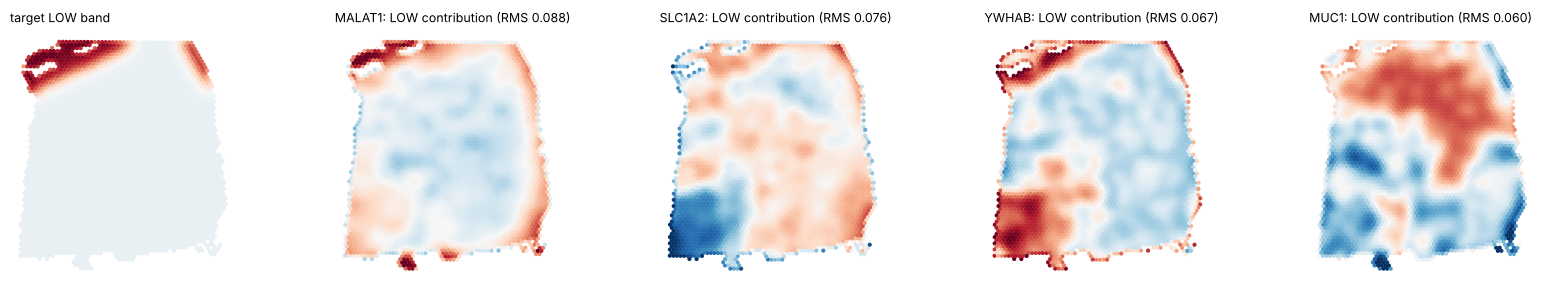

In [6]:
fig = plot_contributions(res, band="LOW", n=4, s=9)

The selected genes are representatives of correlated modules, not the only related genes. `modules` classifies every gene in the dictionary, per band: `selected`; `covered` (correlated with the target but reproducible from the selected set, with its representative named); `relevant-uncovered` (correlated with the target and not covered: what a sparse list silently drops); `unrelated`.

In [7]:
m = res.modules[res.modules.band == "LOW"]
print(m.status.value_counts().to_dict())
m[m.status == "covered"].head(10).round(3)

{'unrelated': 244, 'covered': 226, 'selected': 30}


,gene,band,relevance,coverage,representative,status
0,DHCR24,LOW,0.597,0.759,MUC1,covered
1,DNAJC6,LOW,0.586,0.745,HPCAL1,covered
2,SERINC1,LOW,0.581,0.802,YWHAB,covered
3,NDUFB9,LOW,0.573,0.726,YWHAB,covered
4,PRKACB,LOW,0.570,0.719,YWHAB,covered
5,SLC24A2,LOW,0.556,0.747,HPCAL1,covered
6,BEX4,LOW,0.547,0.759,APBB1,covered
7,TRIM2,LOW,0.546,0.654,STMN4,covered
8,YWHAQ,LOW,0.543,0.789,ATP2A2,covered
9,SEPT7,LOW,0.533,0.757,STMN4,covered


## 3. Moved by one spot, or grown by one ring

The same procedure on two deliberate mistakes. Moving the outline by one lattice step (100 µm) keeps two thirds of its spots; growing it by one ring keeps all of them and adds a boundary.

In [8]:
tree = cKDTree(coords)
nbrs = [A.indices[A.indptr[i]:A.indptr[i + 1]] for i in range(A.shape[0])]

def shift_mask(mask, steps=1):
    # move every spot of the region by `steps` lattice steps toward the tissue centre
    centre = coords.mean(0)
    direction = centre - coords[mask].mean(0); direction /= np.linalg.norm(direction)
    i0 = int(np.argmin(np.linalg.norm(coords - centre, axis=1)))
    lattice = [(coords[j] - coords[i0]) / np.linalg.norm(coords[j] - coords[i0]) for j in nbrs[i0]]
    v = max(lattice, key=lambda w: w @ direction)
    d, idx = tree.query(coords[mask] + steps * pitch_px * v)
    out = np.zeros(len(mask), bool); out[np.unique(idx[d <= 0.6 * pitch_px])] = True
    return out

def dilate_mask(mask, rings=1):
    out = mask.copy()
    for _ in range(rings):
        out = out | np.array([out[nb].any() for nb in nbrs])
    return out

variants = {"as annotated": region, "moved 1 spot": shift_mask(region, 1), "moved 3 spots": shift_mask(region, 3), "grown 1 ring": dilate_mask(region, 1)}
rows = []
for name, mk in variants.items():
    r = sm.explain(counts, genes, coords, mk, pitch_um=100, sigmas=(70, 200), designs=("perband",), null_kinds=(), n_null=0, verbose=False)
    rows.append(dict(version=name, spots=int(mk.sum()), overlap=round(float((mk & region).sum() / region.sum()), 2),
                     A=round(r.scores["perband"]["A"], 3), best=round(r.scores["perband"]["best"], 3)))
pd.DataFrame(rows)

,version,spots,overlap,A,best
0,as annotated,267,1.00,0.547,0.614
1,moved 1 spot,245,0.78,0.411,0.497
2,moved 3 spots,238,0.49,0.118,0.171
3,grown 1 ring,321,1.00,0.490,0.531


The score is a test of placement: a region moved off its structure loses most of it (0.55 to 0.41 for one spot, 0.12 for three), a region that still contains the structure keeps most of it (0.49 when grown by a ring). Over-drawing is penalised only lightly, which is a limitation to keep in mind when the question is how tight a boundary is.

In [9]:
res.save("output/151673_L1")
print(open("output/151673_L1/summary.txt").read())

region target on 3621 units, pitch 100 um, bands 70/200 um
held-out: A = 0.547, best 1-NMSE = 0.614 at k = 17
explained per band (held-out): LOW 0.74, MID 0.05, HIGH -0.11
target band shares: LOW 0.74, MID 0.05, HIGH 0.03
perband/rigid/A: p = 0.048, excess over null mean = +0.510 (n = 20)
perband/rigid/best: p = 0.048, excess over null mean = +0.562 (n = 20)
perband/rigid/explained_MID: p = 0.048, excess over null mean = +0.311 (n = 20)
perband/blob/A: p = 0.048, excess over null mean = +0.421 (n = 20)
perband/blob/best: p = 0.048, excess over null mean = +0.424 (n = 20)
perband/blob/explained_MID: p = 0.048, excess over null mean = +0.507 (n = 20)
top genes (order, dominant band): APBB1 (LOW), MALAT1 (LOW), STMN4 (LOW), HPCAL1 (LOW), EEF2 (LOW), MUC1 (LOW), MORF4L2 (LOW), S100A6 (LOW), SLC1A2 (LOW), YWHAB (LOW)



## Where to go next

* A continuous target (a programme score, a model's probability map) works the same way; see tutorial 2.
* For Visium HD or imaging data use the default bands `sigmas=(40, 200)` and the bin pitch; the MID band then holds structures such as glomeruli.
* `scalematch explain --h5ad ... --pitch-um ... --target-obs ... --out ...` runs the same analysis from the command line.